# N124 - Optimizer forecast support repair

Status: **complete**; complete: **True**. New forks: **384/384**; complete parent/views: **48**.

Compare frozen additive forecasts, positive first-moment norm, and positive five-summary optimizer forecasts. Health outputs, J/H1 objective, margins, displacement and replay rules stay fixed; no online adaptation.

Original: six reused fit histories. Stalled: one shared N115 learner. Heldout: three historical N106 TEST histories excluded from N122/N124 fitting and calibration. Development labels evaluate outcomes only. No independent confirmation, final audit panel, or deployed winner.

## H32 controller change versus frozen

Negative CE is better. Accuracy changes are percentage points. Actual update/reference counts are per 32-arrival fork.

| Cohort | Arm | CE change | Accuracy change | Worst-cell accuracy change | Updates | Reference trials |
|---|---|---:|---:|---:|---:|---:|
| original | frozen | +0.000000 | +0.000 | +0.000 | 25.17 | 18.38 |
| original | moment_log | +0.000000 | +0.000 | +0.000 | 25.17 | 18.38 |
| original | optimizer_log | +0.000000 | +0.000 | +0.000 | 25.17 | 18.38 |
| stalled | frozen | +0.000000 | +0.000 | +0.000 | 17.58 | 16.83 |
| stalled | moment_log | -0.001391 | +0.031 | +0.278 | 32.00 | 32.00 |
| stalled | optimizer_log | -0.001391 | +0.031 | +0.278 | 32.00 | 32.00 |
| heldout | frozen | +0.000000 | +0.000 | +0.000 | 16.00 | 10.33 |
| heldout | moment_log | +0.000000 | +0.000 | +0.000 | 16.00 | 10.33 |
| heldout | optimizer_log | +0.000000 | +0.000 | +0.000 | 16.00 | 10.33 |

## Initial forecast mechanism

Admitted counts list hold/ordinary/refresh/refresh+replay. Error refers to the refresh first-moment norm. Fixed-tail CE measures only the initial selected action, followed by the original frozen controller.

| Cohort | Arm | Admitted counts | Norm MAE | Fixed-tail CE effect | Best action excluded |
|---|---|---|---:|---:|---:|
| original | frozen | [24, 24, 24, 24] | 0.014522 | -0.000176 | 0/24 |
| original | moment_log | [24, 24, 24, 24] | 0.013569 | -0.000176 | 0/24 |
| original | optimizer_log | [24, 24, 24, 24] | 0.013569 | -0.000176 | 0/24 |
| stalled | frozen | [12, 12, 0, 2] | 0.115372 | -0.000136 | 7/12 |
| stalled | moment_log | [12, 12, 12, 12] | 0.050493 | -0.001455 | 0/12 |
| stalled | optimizer_log | [12, 12, 12, 12] | 0.050493 | -0.001455 | 0/12 |
| heldout | frozen | [12, 12, 12, 12] | 0.013426 | -0.000211 | 0/12 |
| heldout | moment_log | [12, 12, 12, 12] | 0.009501 | -0.000211 | 0/12 |
| heldout | optimizer_log | [12, 12, 12, 12] | 0.009501 | -0.000211 | 0/12 |

## Verification and limits

Saved-probability audit passed: **True**. Maximum CE/accuracy reconstruction error: 0.0/0.0. Maximum relative displacement error: 7.22303e-05.

New fork work: 4291 updates, 3247 reference trials; 25.7 summed fork minutes. Prefix/preparation overhead is additional.

Only complete parent/view bundles enter comparisons. Positivity is imposed by construction and is not proof of accurate dynamics. The baseline's health model and margins remain unchanged. A positive result would not establish semantic safety or long-run benefit. The stalled cohort has one shared learner; the heldout cohort has only three histories and is a reused historical source.

See `analysis.json` for action-wise errors, LOHO diagnostics, per-history effects, H1/H8/H32 outcomes, four cells, three-reader sensitivity, health, and work. `input-lock.json` and `source_snapshot/` freeze provenance.

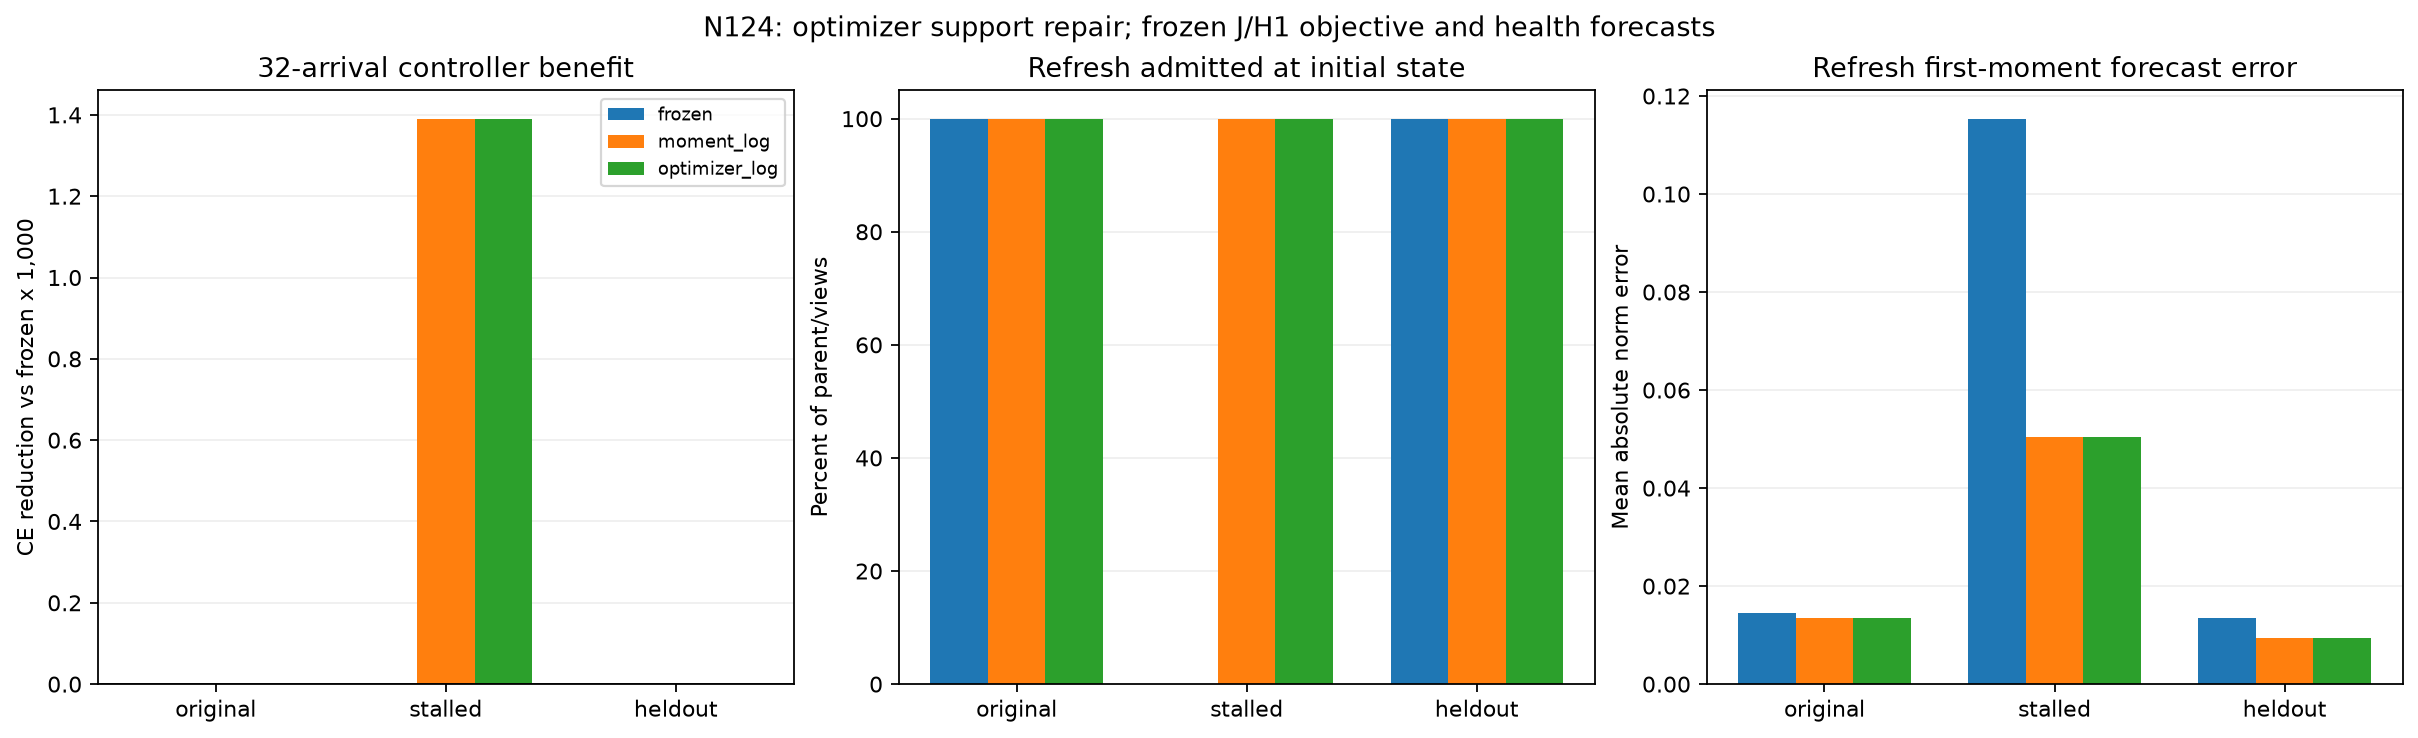


# Interpretation added after collection: a specific controller blockage, not a general MPC improvement

The full experiment completed **384 new forks across 48 parent/views**. The main
finding is that repairing the first-moment forecast removes the diagnosed
stalled-state blockage and modestly improves mean development CE there. It has
no behavioral effect on either the original or held-out input cohorts. Replacing
all five optimizer forecasts adds no behavioral benefit over replacing the
first-moment norm alone.

## What the controlled intervention establishes

All arms use the same frozen health forecasts, J/H1 objective, empirical margins,
replay mechanism and displacement target. At an identical current state, their
health scores are identical. Only optimizer forecasts, and consequently their
validity decisions, differ. The repair fits positive next-level predictions in
log space on the original TRAIN transitions; it does not clip negative outputs.

At the shared stalled learner, the original model admits refresh in **0/12**
parent/views and refresh-plus-replay in **2/12**. Both repairs admit both actions
in **12/12**. Initial choices change from nine holds, one ordinary update and two
refresh-plus-replay updates to refresh-plus-replay in all twelve cases.

This controlled change substantiates N123's diagnosis for these states: the
impossible optimizer forecast was preventing actions that the existing health
objective would otherwise choose. It is not evidence that the same mechanism
explains every deferral in N122's adapting, longer-running controller.

## Controller outcomes after 32 arrivals

The two repairs have identical action trajectories and task outcomes in this run.
Changes below are relative to the original frozen J/H1 controller. Negative CE
is better; accuracy changes are percentage points.

| Cohort | Parent/views | Mean CE change | Accuracy change | Mean worst-cell accuracy change | Updates: original → repaired |
|---|---:|---:|---:|---:|---:|
| Original TRAIN states | 24 | 0 | 0 | 0 | 25.17 → 25.17 |
| Shared stalled learner | 12 | −0.001391 | +0.031 | +0.278 | 17.58 → 32.00 |
| Held-out input histories | 12 | 0 | 0 | 0 | 16.00 → 16.00 |

The zero effects are exact, not rounded lack of statistical significance: all
three arms finish in identical learner/optimizer/RNG states for all 24 original
and all 12 held-out parent/views. These trajectories do not encounter a validity
difference that changes the selected action. Improved forecast accuracy alone
therefore need not change the controller.

The stalled result is modest and heterogeneous. CE improves in seven cases,
worsens in four, and is identical in one. Four of six input-history means improve;
two worsen. One input history contributes approximately **72% of the net mean
gain**. Excluding it still gives a smaller mean improvement, about 0.000474 CE.
The three-reader sensitivity agrees in direction: −0.001365 CE versus −0.001391
for twelve readers. No independent-history confidence claim is appropriate for
the stalled cohort because all inputs share the same initial learner.

## The repair also changes training intensity

Both repaired controllers take **refresh plus replay on every one of the 32
arrivals** at every stalled parent/view. On these measured paths they are
behaviorally equivalent to an always-refresh-plus-replay policy with the same
seeds and actuator. This is not a demonstrated advantage of adaptive selection.

Successful updates rise from 17.58 to 32 per fork, approximately **82% more**.
Ordinary-reference trials rise from 16.83 to 32, approximately **90% more**. Mean
measured fork duration rises from about 7.03 seconds to 10.47 seconds for the
first-moment repair, about 49%; this includes feature/readout overhead and is not
a hardware-independent cost estimate. The comparison matches displacement per
update, not total updates or compute. It cannot establish a gain in efficiency.

## Post-hoc continuation decomposition

N123 already measured each first action followed by the original frozen J/H1
policy. These saved forks allow an additional paired comparison without training
another learner. We verified that selecting the baseline's first action from
those forks exactly reproduces its N124 H32 probabilities.

| Stalled intervention | Mean CE change versus full baseline | Mean updates |
|---|---:|---:|
| Repair only the initial decision, then use the original controller | −0.001319 | 30.08 |
| Use the repaired controller throughout | −0.001391 | 32.00 |

Changing just the initial decision recovers approximately **94.9% of the full
mean CE gain**. This is a ratio of cohort means, not a universal per-case property.
It suggests that releasing the initial blockage accounts for most of the
aggregate benefit. Once that first update changes the state, the original
controller often continues training successfully.

This does **not** mean 95% of the benefit is obtained at the original cost:
the original continuation after the repaired initial decision itself performs
many more updates. This post-hoc decomposition remains confounded with training
intensity and needs a budget-matched comparison before an efficiency claim.

## Forecast quality: narrower success than positivity alone suggests

Refresh first-moment norm MAE improves at the measured initial states:

| Cohort | Additive predictor | Log predictor |
|---|---:|---:|
| Original | 0.014522 | 0.013569 |
| Stalled | 0.115372 | 0.050493 |
| Held-out | 0.013426 | 0.009501 |

However, whole-history cross-validation on the broader original transition set
does not favor a general switch to log prediction. Mean first-moment MAE for
ordinary updates rises from 0.023476 to 0.089129; refresh rises from 0.019636 to
0.021381; refresh-plus-replay rises from 0.029672 to 0.039722. These diagnostics
include measured first and second transitions and differ from the small initial
state census above. Positive support is imposed by construction, and it does
not make the predictor globally more accurate.

Repairing all five optimizer summaries changes no controller outcomes beyond
the one-coordinate repair. Its broader forecast errors provide no reason to
prefer that additional intervention here.

## What this says about health metrics and MPC

The evidence supports treating forecast validity as a separate engineering
requirement from task utility. At these stalled states, invalid optimizer
predictions block the health objective. Correcting that gate lets the objective
act, but the result is effectively an always-refresh-plus-replay policy.

Health metrics remain useful state observations and forecasting targets. They
are not established semantic-retention guarantees. Although all four mean cell
CE changes improve in the stalled cohort, two cell accuracies fall by roughly
0.181 and 0.097 percentage points. Mean accuracy barely changes. Neither the
positive optimizer output nor the unchanged health margins establishes safety
for every task cell.

N123's continuation-dependent value finding is not overturned. N124 changes
action availability under a fixed J/H1 objective; it does not qualify an H2
terminal value, a richer capability critic, or a longer planning horizon.

## Recommended next step

Keep the repair narrow. For immediate optimizer-state feasibility, investigate
using the known optimizer update and the available candidate gradient rather
than learning an unconstrained norm delta. A positive learned predictor can be a
fallback, but these results do not qualify a global replacement with log outputs.

The next behavioral comparison should include a one-time recovery intervention,
fixed refresh-plus-replay, and the repaired J/H1 controller under matched training
budgets. Use multiple independently generated late/stalled learner states, with
held-out input histories and the same task-cell readouts. This would test whether
the controller adds value beyond unblocking training and increasing its amount.
Only after that should a first-action value target aligned with the deployed
continuation be compared with the health-only objective. Expanding the critic
or horizon remains premature.

## Verification and scope

The main saved-probability audit reconstructs CE and accuracy exactly. All 5,020
locked source/input hashes and 384 new case hashes passed an independent audit.
Directly decoding coefficients reproduced all 6,336 saved action slots and all
27 paired behavior summaries; maximum optimizer-forecast discrepancy was
3.33e−16. This is independent arithmetic verification, not a second GPU experiment.

The held-out cohort consists of three historical N106 TEST input histories,
excluded from N122/N124 fitting and margin calibration, but not pristine project
test data. The development panel is reused. The stalled cohort shares one
online-derived learner. No live learner was committed, no final audit panel was
loaded, and this study does not qualify deployment or long-run retention.

Artifacts: the original frozen-protocol report and arrays remain in
`project/cafl4ds/outputs/optimizer-support-repair/20261031-n124/`. This directory
contains `independent-verification.json`, the reproducible independent audit, and
`continuation-decomposition.json` with the explicitly post-hoc comparison.
